# Position decoding from raw and latent hippocampal LFP

**Question:** Can CA1 LFP predict sequence position (1st–5th), and does a compact CEBRA representation preserve useful decoding information?

One experiment per rat. Compare the same L2-regularized logistic-regression decoder on:
1. Raw, normalized 0–500 ms LFP windows.
2. CEBRA-Time trained only on training odor windows.
3. CEBRA-Time trained on the broader training recording, including time outside odor windows.

CEBRA receives no odor, position, correctness, or InSeq labels. This is a preliminary single-split experiment, not evidence that CEBRA must outperform raw LFP. The reusable implementation is in `src/position_pipeline.py` so both task groups can share preprocessing.


## Setup and portable paths
Use the existing `.venv-cebra` notebook kernel. Run from this repository or its `notebooks` directory. Data can live in this repository's `data/raw_data` or in the parent Capstone `data/raw_data`. Set `OST_DATA` for another location. No personal directory is embedded below.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, warnings
warnings.filterwarnings('ignore', message='.*torch.jit.script.*', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'position_pipeline.py').is_file())
sys.path.insert(0, str(REPO / 'src'))
from position_pipeline import Config, run_session, SegmentSampler

if os.environ.get('OST_DATA'):
    DATA = Path(os.environ['OST_DATA']).expanduser().resolve()
else:
    DATA = next((p for p in [REPO/'data'/'raw_data', REPO.parent/'data'/'raw_data']
                 if any(p.glob('*/*_bvr.npz'))), None)
    if DATA is None:
        raise FileNotFoundError('Set OST_DATA to the raw_data directory.')
SESSIONS = sorted(p.parent.name for p in DATA.glob('*/*_bvr.npz'))
assert len(SESSIONS) == 5, f'Expected all five rats, found {SESSIONS}'
CFG = Config()
# Optional: set POSITION_REUSE_RUN to an existing completed results folder.
REUSE = os.environ.get('POSITION_REUSE_RUN')
RUN = Path(REUSE).resolve() if REUSE else REPO / 'results' / ('position_cebra_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
if not REUSE:
    RUN.mkdir(parents=True, exist_ok=False)
else:
    assert RUN.is_dir()
print('Python:', sys.version.split()[0], '| environment:', Path(sys.prefix).name)
print('Sessions:', SESSIONS)
print('Configuration:', CFG)


Python: 3.12.13 | environment: .venv-cebra
Sessions: ['080718_mitt', '081106_barat', '090212_stella', '090212_superchris', '090420_buchanan']
Configuration: Config(fs=1000, window_ms=500, artifact_z=20.0, train_fraction=0.7, validation_fraction=0.15, architecture='offset10-model', positive_offset_ms=100, latent_dim=8, hidden_units=32, iterations=1000, batch_size=512, learning_rate=0.0003, seed=42, n_null=20, c_grid=(0.01, 0.1, 1.0))


## Shared preprocessing and the fixes

- Reconstruct odor events, position, correctness, and nose-poke intervals from `raw_data`. Labels are 0–4 internally; figures display 1–5. Supplied epoched tensors are not used because their behavioral alignment needs independent verification.
- Build conservative sequence groups **before exclusions**, starting at each recorded position-1 event. Keep initial partial sequences together. Missing starts merge stretches into one group, instead of creating a possibly unsafe split. Flag missing/repeated positions with `sequence_group_irregular`. These inferred groups are not supplied ground-truth sequence IDs.
- Allocate approximately 70/15/15 **whole conservative sequence groups** chronologically. No group crosses a split. The recording boundary is the next block's first nose-poke entry. Training statistics and pretraining stop before validation. Rat-specific models avoid treating channel names as anatomical correspondence.
- Match the odor group's 500 ms window, 1,000 Hz sampling, training-derived amplitude/jump threshold (20 robust standard deviations), and training-only channel z-score. No filtering, notch removal, or resampling. Include both correctness types and both InSeq/OutSeq types. Drop windows crossing recording/split boundaries or withdrawal.
- Report rejected trials by position and trial type. A 500 ms minimum sampling duration can selectively remove OutSeq trials. The artifact threshold is a shared initial policy, not a validated biological cutoff. Inspect QC before treating results as final.
- The CEBRA temporal sampler draws only valid convolutional contexts within one clean continuous segment. The entire bridge to the positive stays in the same segment. It never crosses a trial boundary, artifact, timestamp gap, or split.

The 10-sample encoder has a **10 ms receptive field at 1,000 Hz**. Its positive-pair lag is separately set to 100 ms. Trial embeddings average valid encoder outputs without padding or neighboring trials.


## Boundary sampler check
This small check verifies the key temporal invariant on disconnected synthetic segments. Full recording integrity and sequence ownership are also asserted during preprocessing.


In [2]:
segments = [(0, 500), (800, 1300), (2000, 2600)]
sampler = SegmentSampler(segments, left=5, right=5, lag=100, seed=42)
ref, pos, neg = sampler.triplet(10000)
for a, b in zip(ref, pos):
    assert any(start <= a-5 and b+5 <= end for start, end in segments)
for a in neg:
    assert any(start <= a-5 and a+5 <= end for start, end in segments)
print('Passed: all sampled contexts and temporal bridges stay inside a real segment.')


Passed: all sampled contexts and temporal bridges stay inside a real segment.


## Run all rats

Each encoder uses 1,000 updates and eight latent dimensions. Both encoders start from the same seed and use the same update budget. Logistic-regression strength is selected from C = 0.01, 0.1, 1 using validation balanced accuracy. The decoder remains trained on training trials only. Test scores never select preprocessing, CEBRA settings, or decoder parameters.

The shuffled-label benchmark refits the decoder with permuted training labels and a fixed selected C. It is **descriptive**, not a sequence-aware significance test. Repeated seeds, whole-sequence folds, and a suitable temporal null are needed for final inference.

Outputs are local, ignored by Git, and isolated in a timestamped directory. Training uses CEBRA's official encoder and cosine InfoNCE loss through its lower-level PyTorch interface, with a custom boundary-safe sampler rather than an unverified flattened-trial adapter.


In [3]:
if REUSE:
    all_metrics, manifests, confusions, loss_histories = [], [], {}, {}
    for session in SESSIONS:
        folder = RUN/session
        meta = json.loads((folder/'run_metadata.json').read_text())
        assert meta['config'] == json.loads(json.dumps(CFG.__dict__)), 'Cached configuration differs'
        all_metrics.append(pd.read_csv(folder/'metrics.csv'))
        manifests.append(pd.read_csv(folder/'trial_manifest.csv', keep_default_na=False).assign(session=session))
        confusions[session] = {name: pd.read_csv(folder/f'{name}_confusion.csv', index_col=0).to_numpy()
                              for name in ['raw', 'cebra_trial_only', 'cebra_recording']}
        loss_histories[session] = pd.read_csv(folder/'cebra_losses.csv').to_dict('list')
    metrics = pd.concat(all_metrics, ignore_index=True)
    manifest = pd.concat(manifests, ignore_index=True)
    print('Loaded completed results. No models were retrained.')
else:
    all_metrics, manifests, confusions, loss_histories = [], [], {}, {}
    for session in SESSIONS:
        metrics, manifest, cms, losses = run_session(DATA, session, RUN, CFG)
        all_metrics.append(metrics)
        manifests.append(manifest)
        confusions[session] = cms
        loss_histories[session] = losses
        pd.concat(all_metrics, ignore_index=True).to_csv(RUN/'metrics_all_rats.csv', index=False)
    metrics = pd.concat(all_metrics, ignore_index=True)
    manifest = pd.concat(manifests, ignore_index=True)
    manifest.to_csv(RUN/'trial_manifest_all_rats.csv', index=False)
    print('Run complete.')


Loaded completed results. No models were retrained.


## Retention and class coverage
Check small test sets before interpreting scores. Sequence-group percentages are not guaranteed to equal trial percentages. Irregular groups can contain missing events or multiple sequences with missing starts. Grouping conservatively prevents those stretches from straddling a split, but exact sequence reconstruction should be checked with the lab for final analysis. Accepted trials and split IDs are identical across the three representations.


In [4]:
display(manifest.groupby(['session', 'split']).agg(
    trials=('trial_id', 'size'), sequences=('sequence_id', 'nunique'),
    retained=('retained', 'sum')))
display(manifest.groupby('session').sequence_group_irregular.sum().rename('trials_in_irregular_groups').to_frame())
display(pd.crosstab([manifest.session, manifest.inseq], manifest.retained))
display(pd.crosstab([manifest.session, manifest.position + 1], manifest.retained))
print('Exclusion reasons:')
display(manifest[~manifest.retained].groupby(['session', 'reasons']).size().rename('n').to_frame())
kept = manifest[manifest.retained]
display(pd.crosstab([kept.session, kept.split], kept.position + 1))


trials  sequences  retained
session           split                                  
080718_mitt       test            52         13        48
                  train          201         55       195
                  validation      39         11        39
081106_barat      test            23          8        23
                  train          125         35       125
                  validation      28          7        28
090212_stella     test            41         10        40
                  train          156         40       146
                  validation      25          8        24
090212_superchris test            45         10        43
                  train          161         39       158
                  validation      34          8        32
090420_buchanan   test            47         13        46
                  train          183         53       183
                  validation      40         11        40

,trials_in_irregular_groups
session,
080718_mitt,4
081106_barat,4
090212_stella,13
090212_superchris,22
090420_buchanan,116


retained                 False  True 
session           inseq              
080718_mitt       False      0     30
                  True      10    252
081106_barat      False      0     21
                  True       0    155
090212_stella     False     10     18
                  True       2    192
090212_superchris False      5     25
                  True       2    208
090420_buchanan   False      0     44
                  True       1    225

retained                    False  True 
session           position              
080718_mitt       1             5     74
                  2             0     63
                  3             1     57
                  4             0     51
                  5             4     37
081106_barat      1             0     49
                  2             0     37
                  3             0     35
                  4             0     29
                  5             0     26
090212_stella     1             0     58
                  2             2     47
                  3             6     38
                  4             2     36
                  5             2     31
090212_superchris 1             0     56
                  2             1     56
                  3             2     45
                  4             1     42
                  5             3     34
090420_buchanan   1             0     76
                  2             0     57
                  3             0     41
                  4             0     49
                  5             1     46

Exclusion reasons:


n
session           reasons                             
080718_mitt       early_withdrawal                  10
090212_stella     early_withdrawal                  12
090212_superchris amplitude_artifact                 2
                  amplitude_artifact;jump_artifact   1
                  early_withdrawal                   4
090420_buchanan   early_withdrawal                   1

position                       1   2   3   4   5
session           split                         
080718_mitt       test        13  12  10   9   4
                  train       50  42  40  36  27
                  validation  11   9   7   6   6
081106_barat      test         8   5   4   3   3
                  train       34  25  25  22  19
                  validation   7   7   6   4   4
090212_stella     test        10   9   7   7   7
                  train       40  33  27  25  21
                  validation   8   5   4   4   3
090212_superchris test        10   9   9   9   6
                  train       38  40  30  28  22
                  validation   8   7   6   5   6
090420_buchanan   test        13  13   7   7   6
                  train       52  34  27  36  34
                  validation  11  10   7   6   6

## Raw versus latent position decoding
Balanced accuracy is mean recall across target classes present. For five represented classes its uniform-chance reference is 0.20. Subsets may omit classes, so their class count is printed explicitly and their scores are not directly interchangeable. Macro-F1 uses all five classes. Results are independent fits per rat, not a pooled cross-rat decoder.


method,cebra_recording,cebra_trial_only,raw
session,,,
080718_mitt,0.159,0.134,0.348
081106_barat,0.240,0.337,0.440
090212_stella,0.502,0.566,0.506
090212_superchris,0.389,0.367,0.344
090420_buchanan,0.282,0.321,0.273


,session,method,n,n_classes,chosen_C,validation_balanced_accuracy,shuffle_mean,shuffle_95_percentile
0,080718_mitt,raw,48,5,0.01,0.294,0.182,0.240
3,080718_mitt,cebra_trial_only,48,5,1.00,0.274,0.190,0.301
6,080718_mitt,cebra_recording,48,5,1.00,0.309,0.194,0.233
9,081106_barat,raw,23,5,0.01,0.260,0.216,0.379
12,081106_barat,cebra_trial_only,23,5,1.00,0.233,0.182,0.320
15,081106_barat,cebra_recording,23,5,1.00,0.300,0.188,0.295
18,090212_stella,raw,40,5,1.00,0.447,0.185,0.279
21,090212_stella,cebra_trial_only,40,5,0.10,0.345,0.189,0.388
24,090212_stella,cebra_recording,40,5,1.00,0.512,0.217,0.313
27,090212_superchris,raw,43,5,0.01,0.327,0.193,0.312


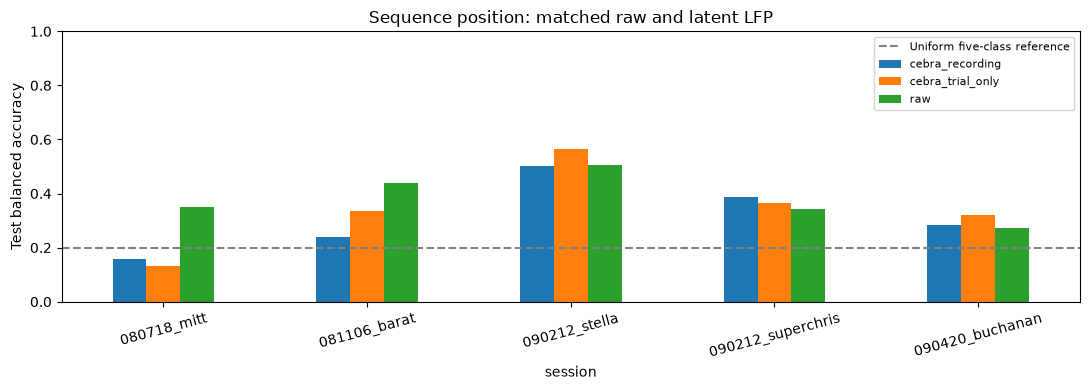

In [5]:
main = metrics[metrics.subset.eq('all')]
comparison = main.pivot(index='session', columns='method', values='balanced_accuracy')
display(comparison.round(3))
display(main[['session', 'method', 'n', 'n_classes', 'chosen_C',
              'validation_balanced_accuracy', 'shuffle_mean', 'shuffle_95_percentile']].round(3))
fig, ax = plt.subplots(figsize=(11, 4))
comparison.plot.bar(ax=ax, rot=15)
ax.axhline(.2, color='gray', linestyle='--', label='Uniform five-class reference')
ax.set(ylabel='Test balanced accuracy', ylim=(0, 1), title='Sequence position: matched raw and latent LFP')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RUN/'position_comparison.png', dpi=150)
plt.show()


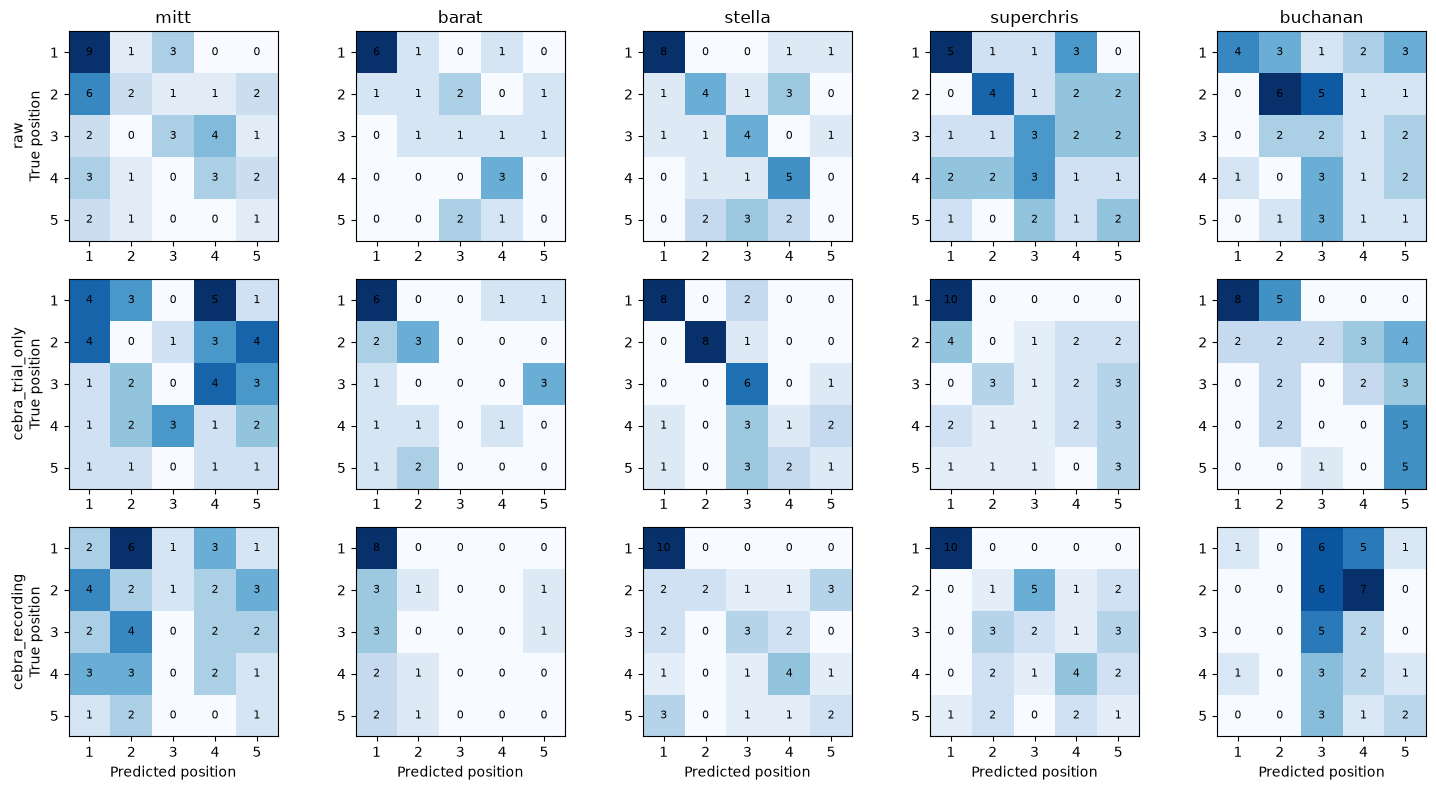

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
methods = ['raw', 'cebra_trial_only', 'cebra_recording']
for row, method in enumerate(methods):
    for col, session in enumerate(SESSIONS):
        ax = axes[row, col]
        cm = confusions[session][method]
        ax.imshow(cm, cmap='Blues')
        for i in range(5):
            for j in range(5):
                ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=8)
        ax.set(title=session.split('_', 1)[1] if row == 0 else '',
               xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6),
               xlabel='Predicted position' if row == 2 else '',
               ylabel=method + '\nTrue position' if col == 0 else '')
fig.tight_layout(); fig.savefig(RUN/'position_confusions.png', dpi=150)
plt.show()


## Odor–position control
On InSeq trials odor identity equals expected sequence position. An accurate position decoder could therefore recognize odor instead. OutSeq performance is a useful descriptive check, but differences in correctness, movement, duration, and sparse class coverage limit the interpretation.

The odor-only behavioral baseline predicts the most frequent training position for each odor. It shows how much position information comes from odor alone, without using neural data. It is a confounding benchmark, not a competing neural decoder. OutSeq predictions also report how often the predicted position equals the odor's usual position.

Per-odor breakdowns are exploratory. Sparse or missing combinations prevent a definitive claim that position and odor are separately represented. Position 1 may have no alternative odors in this dataset.


,session,method,n,n_classes,accuracy,balanced_accuracy
2,080718_mitt,raw,5,2,0.20,0.125
5,080718_mitt,cebra_trial_only,5,2,0.00,0.000
8,080718_mitt,cebra_recording,5,2,0.20,0.125
11,081106_barat,raw,4,2,0.00,0.000
14,081106_barat,cebra_trial_only,4,2,0.25,0.167
17,081106_barat,cebra_recording,4,2,0.00,0.000
20,090212_stella,raw,4,2,0.00,0.000
23,090212_stella,cebra_trial_only,4,2,0.25,0.500
26,090212_stella,cebra_recording,4,2,0.00,0.000
29,090212_superchris,raw,4,3,0.25,0.333


080718_mitt odor-only test balanced accuracy: 0.894
081106_barat odor-only test balanced accuracy: 0.83
090212_stella odor-only test balanced accuracy: 0.892
090212_superchris odor-only test balanced accuracy: 0.911
090420_buchanan odor-only test balanced accuracy: 0.828


,session,method,n,position_hit_rate,odor_following_rate
0,080718_mitt,raw,5,0.20,0.200
1,080718_mitt,cebra_trial_only,5,0.00,0.200
2,080718_mitt,cebra_recording,5,0.20,0.200
3,081106_barat,raw,4,0.00,0.500
4,081106_barat,cebra_trial_only,4,0.25,0.000
5,081106_barat,cebra_recording,4,0.00,0.000
6,090212_stella,raw,4,0.00,0.250
7,090212_stella,cebra_trial_only,4,0.25,0.000
8,090212_stella,cebra_recording,4,0.00,0.000
9,090212_superchris,raw,4,0.25,0.000


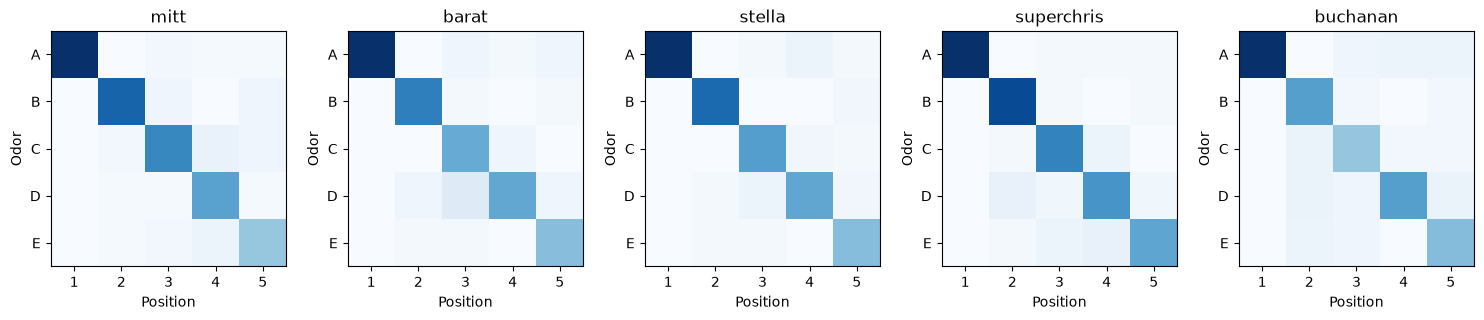

In [7]:
display(metrics[metrics.subset.eq('outseq')][
    ['session', 'method', 'n', 'n_classes', 'accuracy', 'balanced_accuracy']].round(3))
controls = []
for session in SESSIONS:
    meta = json.loads((RUN/session/'run_metadata.json').read_text())
    print(session, 'odor-only test balanced accuracy:', round(meta['odor_only_test_balanced_accuracy'], 3))
    for method in ['raw', 'cebra_trial_only', 'cebra_recording']:
        p = pd.read_csv(RUN/session/f'{method}_predictions.csv')
        out = p[~p.inseq]
        controls.append(dict(session=session, method=method, n=len(out),
            position_hit_rate=(out.prediction == out.position).mean(),
            odor_following_rate=(out.prediction == out.odor).mean()))
        by_odor = p.groupby('odor')[['position', 'prediction']].apply(lambda g: pd.Series({
            'n': len(g), 'n_positions': g.position.nunique(),
            'position_accuracy': (g.prediction == g.position).mean()}))
        by_odor.to_csv(RUN/session/f'{method}_within_odor_test.csv')
controls = pd.DataFrame(controls)
controls.to_csv(RUN/'outseq_controls.csv', index=False)
display(controls.round(3))
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, session in zip(axes, SESSIONS):
    path = RUN/session/'odor_position_counts.csv'
    table = pd.read_csv(path, index_col=0)
    ax.imshow(table, cmap='Blues')
    ax.set(title=session.split('_', 1)[1], xlabel='Position', ylabel='Odor',
           xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=list('ABCDE'))
fig.tight_layout(); fig.savefig(RUN/'odor_position_counts.png', dpi=150)
plt.show()


## Inspect the encoder and signals
Loss convergence does not prove decoding quality. Visual QC is still needed for the shared 20-MAD artifact threshold. Example traces below are normalized held-out signals, before any latent transformation. Full source windows, scaling statistics, exclusions, class counts, loss traces, weights, and predictions are saved for audit.


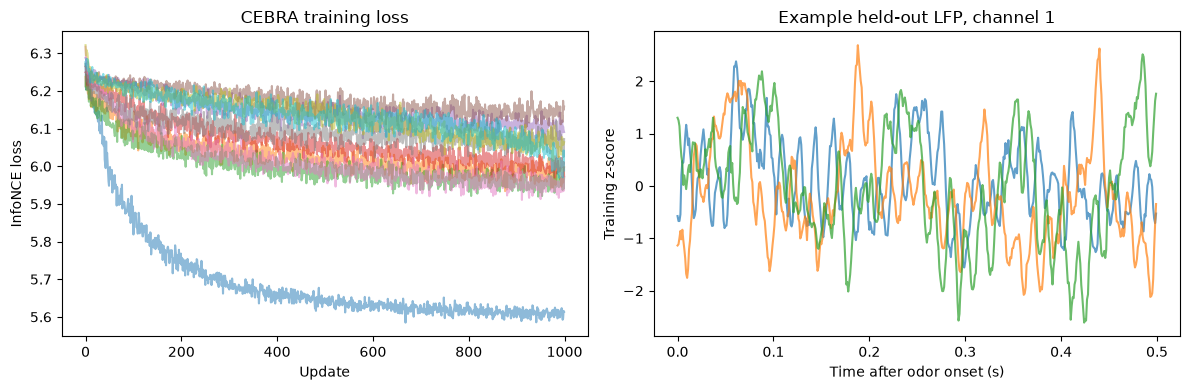

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for session, losses in loss_histories.items():
    for method, values in losses.items():
        axes[0].plot(values, alpha=.5, label=f'{session.split("_", 1)[1]} {method}')
axes[0].set(title='CEBRA training loss', xlabel='Update', ylabel='InfoNCE loss')
with np.load(RUN/SESSIONS[0]/'shared_trials.npz') as z:
    test = np.flatnonzero(z['split'] == 'test')[:3]
    for i in test:
        axes[1].plot(np.arange(z['lfp'].shape[1])/CFG.fs, z['lfp'][i, :, 0], alpha=.7)
axes[1].set(title='Example held-out LFP, channel 1', xlabel='Time after odor onset (s)', ylabel='Training z-score')
fig.tight_layout(); fig.savefig(RUN/'training_and_signal_qc.png', dpi=150)
plt.show()


## Interpretation and next steps
- Compare `cebra_recording` with `cebra_trial_only` to assess additional unlabeled training data at a matched update budget. Different sampling distributions and limited training mean a difference is not a universal pretraining benefit.
- Compare either latent input with `raw` to assess usefulness for the same decoder. Latent mean pooling and raw flattening use the same 500 ms signal support but are different summaries.
- Report each rat, test counts, OutSeq coverage, and odor confounding. Do not infer a separate position code from InSeq accuracy alone.
- This is one seed and one chronological split. Do not select settings after looking at test results. For final estimates, add repeated whole-sequence evaluation, confidence intervals at the sequence/rat level, and a pre-specified control design.
- Both groups should reuse the saved `shared_trials.npz` and `trial_manifest.csv`. Odor decoding changes the target to `odor`, while keeping trial selection, splits, preprocessing, and the decoder tuning procedure matched.

References: [CEBRA hippocampus example](https://cebra.ai/docs/demo_notebooks/Demo_hippocampus.html), [CEBRA model API](https://cebra.ai/docs/api/sklearn/cebra.html), [CEBRA-Time example](https://cebra.ai/docs/demo_notebooks/Demo_openscope_databook.html), and the supplied odor preprocessing PDF. Sequence position is categorical here, unlike continuous track location in the hippocampus demo.
